# Correlagram Supplemental Figure for TSP' s 2, 14, 21, 25, 27
## Version 2d data
## November 24, 2024

## General Import Functions

### Note this was made on my Mac Laptop, which has tspex in the conda env. I didn't ever install it on Sherlock, but rather replaced it with my own code. See TF_Fig2_09-02-26 for that little piece of code to make this run on Sherlock.

In [4]:
#import tspex
import pandas as pd
import scipy.stats as stats
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
#from matplotlib_venn import venn2
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

## filename switching functions

In [9]:
DATA_IN_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/' 
DATA_OUT_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'  
DATA_OUT_DIR = '/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/'  
META_DATA  = 'TSP1_30_version2d_10X_SS_2024_11_12_metadata_CLEAN_TFonly.csv'


CT_DATA_PT1_ = 'TFonly/TSP1_30_by_CellType_'
_CT_DATA_PT2 = '_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv'


TFxCT_DATA = 'TSP1_30_by_CellType_Full_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv'
META_DATA  = 'TSP1_30_version2d_10X_SS_2024_11_12_metadata_CLEAN_TFonly.csv'

COLOR_TABLE = 'CellTypeColorPalettes.csv'


## Iterate through donors

In [20]:
#major donors 
donorlist = ['TSP2', 'TSP14', 'TSP21', 'TSP25', 'TSP27']
all_Tau_df = pd.DataFrame(columns = donorlist)

for donor in donorlist:
    print(DATA_IN_DIR + CT_DATA_PT1_ + donor + _CT_DATA_PT2)
    TF_mean = pd.read_csv(DATA_IN_DIR + CT_DATA_PT1_ + donor + _CT_DATA_PT2, index_col = 0)

    ####################################################################
    # Compute tau specificity value for each TF for a donor
    ####################################################################
    tau_values = pd.Series( index = TF_mean.index, dtype=float)
    for gene in TF_mean.index:
        genevector = TF_mean.loc[gene]
        normed = genevector/max(genevector)
        oneminus = 1 - normed
        tau_values.loc[gene] = sum(oneminus) / (len(oneminus) - 1)

    all_Tau_df[donor] = tau_values

all_Tau_df 
    

/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/TSP1_30_by_CellType_TSP2_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv
/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/TSP1_30_by_CellType_TSP14_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv
/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/TSP1_30_by_CellType_TSP21_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv
/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/TSP1_30_by_CellType_TSP25_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv
/oak/stanford/groups/quake/jonesbob/TF_TS_Analysis_Final_Manuscript/TFonly/TSP1_30_by_CellType_TSP27_Version2d_Nov2024_LogNorm_10XOnly_Mean_TFonly.csv


,TSP2,TSP14,TSP21,TSP25,TSP27
index,,,,,
NFYA,0.861202,0.776121,0.662243,0.946324,0.938790
ARX,0.983060,0.994027,0.989378,0.985533,0.981789
HOXA11,0.961485,0.993388,0.974153,0.991928,0.995623
MEOX1,0.966188,0.961391,0.967727,0.983382,0.956545
SOX8,0.985142,0.967738,0.975060,0.976949,0.974849
...,...,...,...,...,...
PCGF2,0.832446,0.845102,0.867736,0.930240,0.920005
ZNF670,0.820709,0.900090,0.918842,0.864776,0.931067
ZNF8,0.815972,0.819348,0.727271,0.870419,0.901540


In [21]:
# remove TFs that are NaN (0/0: not expressed in any cell type) or zero in any donor
all_Tau_df_filtered = all_Tau_df.dropna()
all_Tau_df_filtered = all_Tau_df_filtered.loc[~(all_Tau_df_filtered == 0).any(axis=1)]

In [22]:
all_Tau_df.isna().sum()

TSP2     11
TSP14     5
TSP21     9
TSP25     2
TSP27     9
dtype: int64

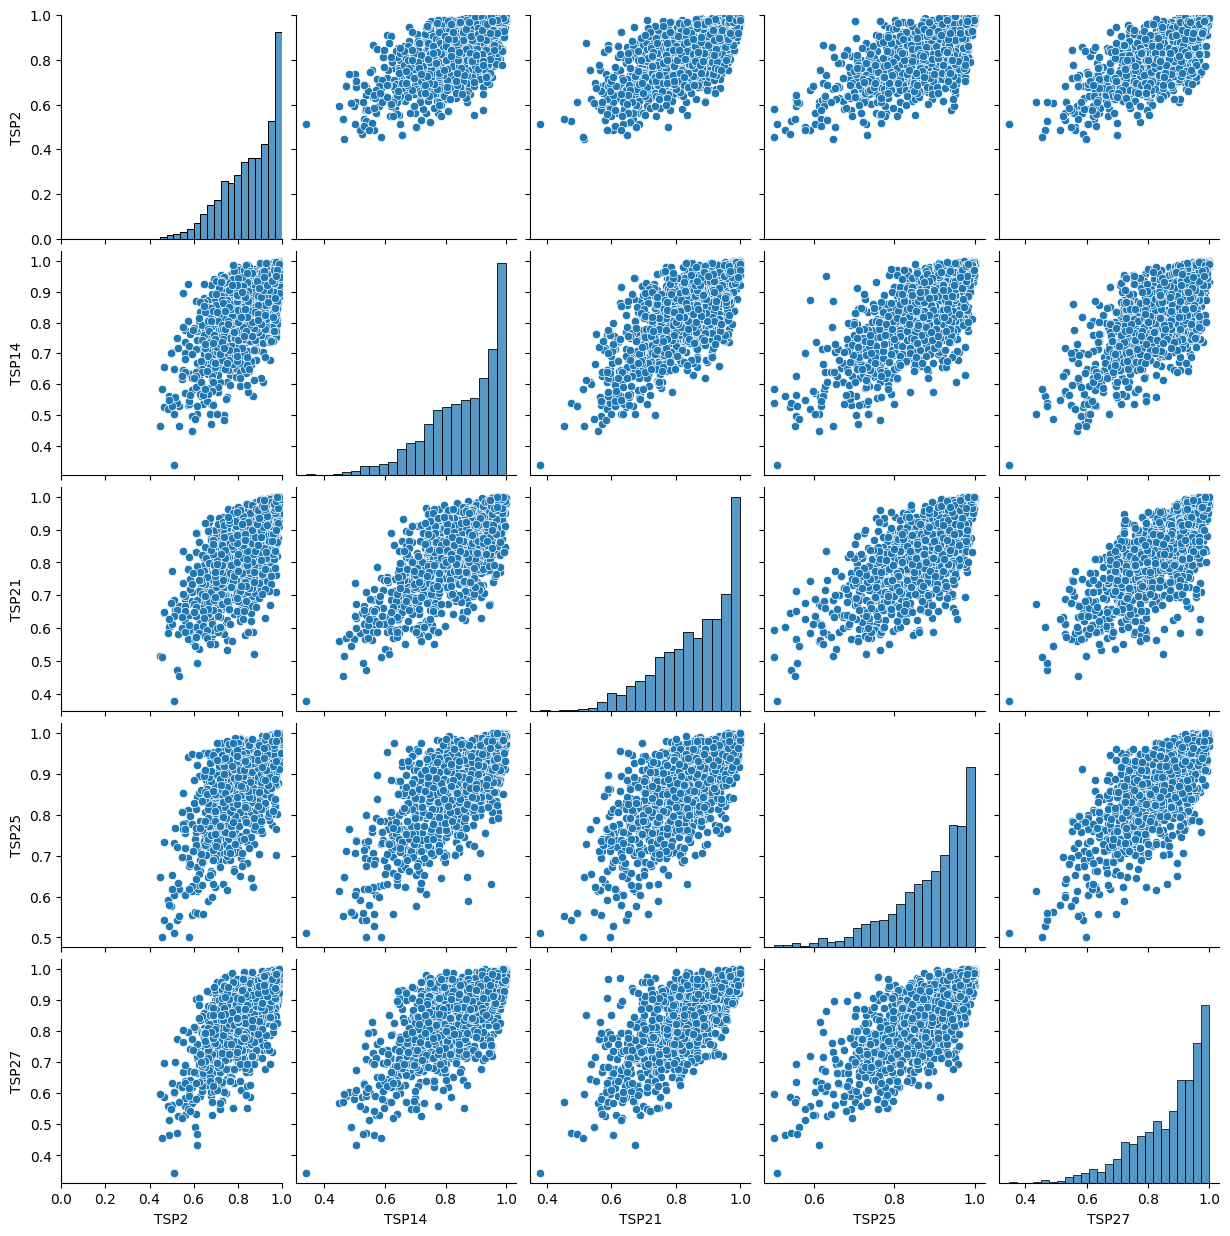

In [23]:
g = sns.pairplot(all_Tau_df, kind="scatter")
plot_kws={"s": 5}
g.axes[0,0].set_ylim((0,1))
g.axes[0,0].set_xlim((0,1))
plt.show()

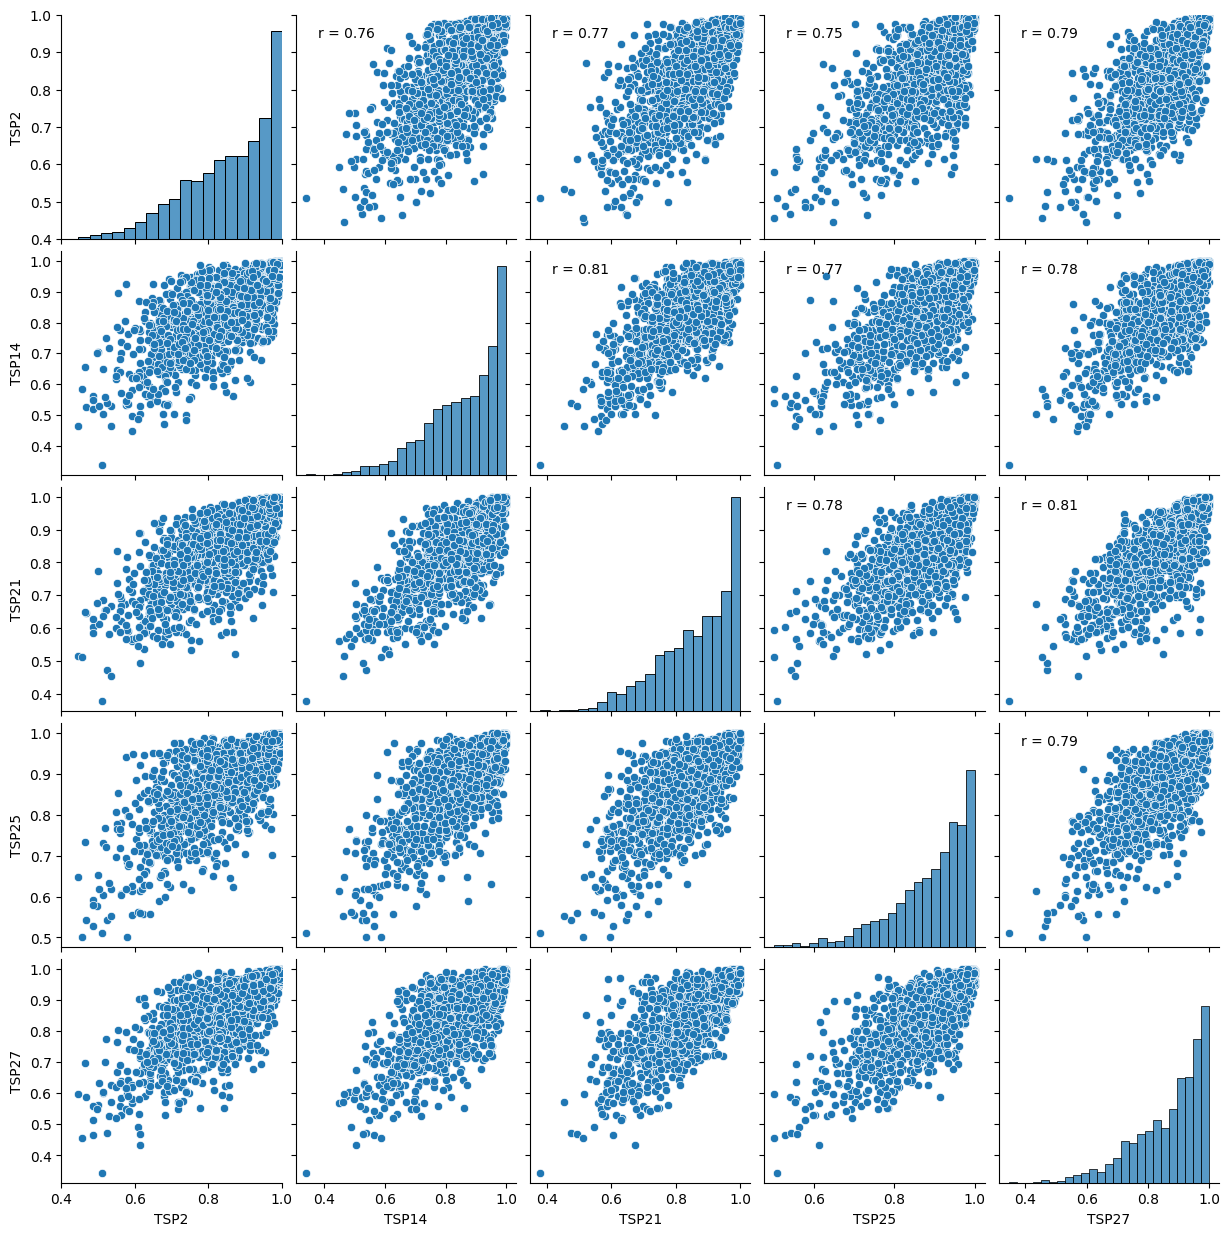

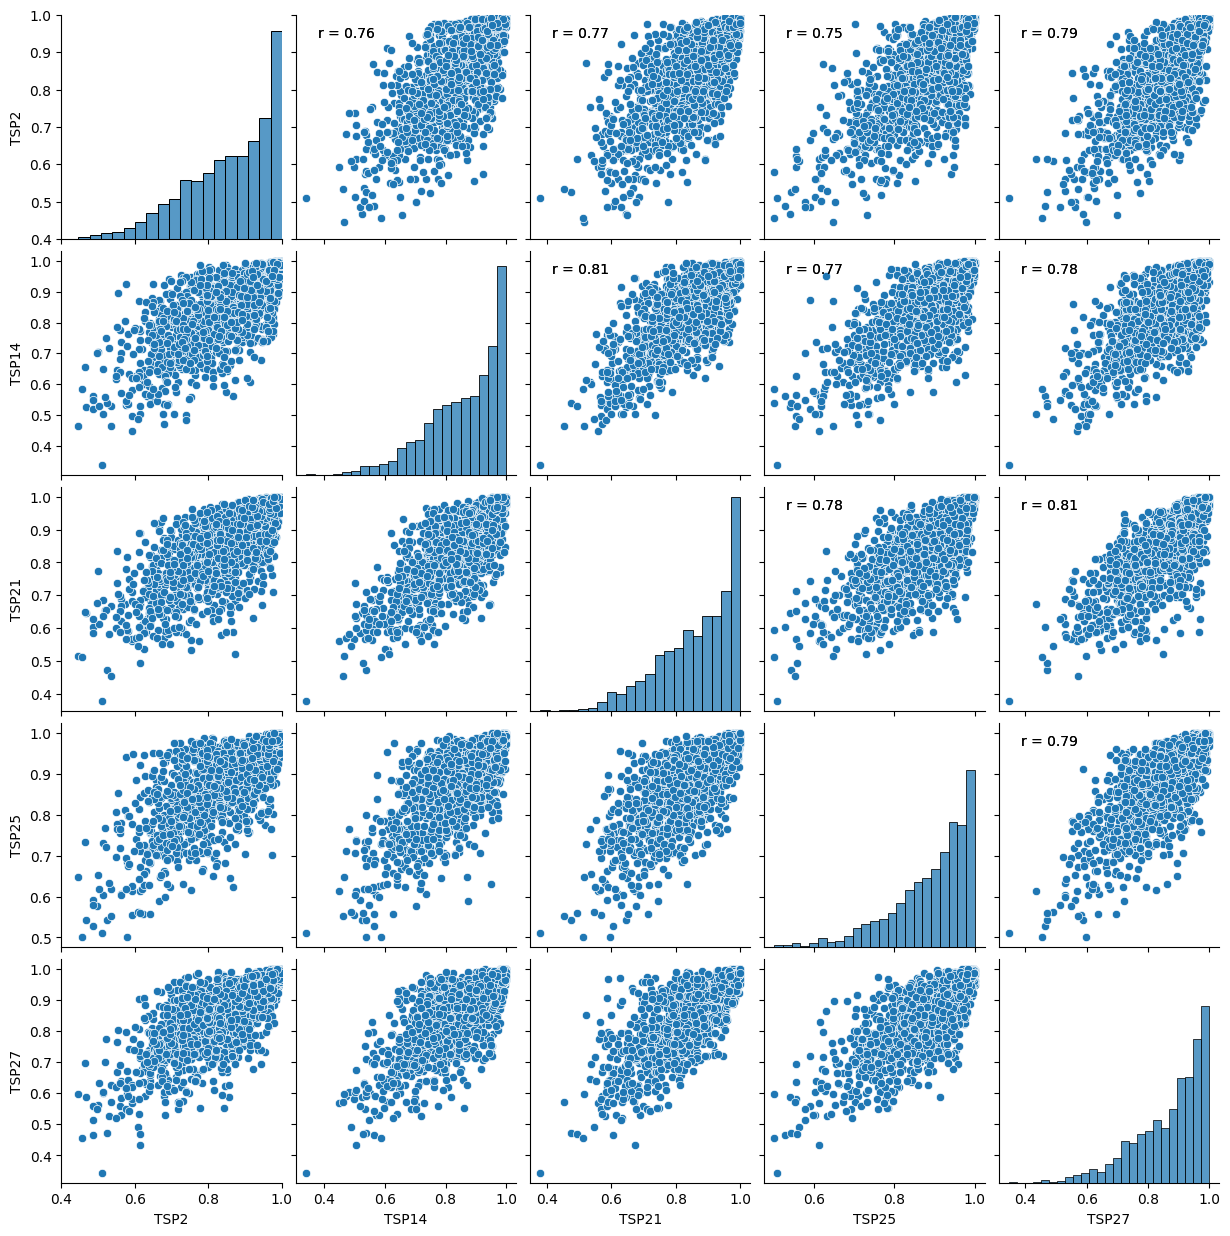

In [25]:
def corrfunc(x, y, **kws):
    r, _ = np.corrcoef(x, y)[0, 1], 0
    ax = plt.gca()
    ax.annotate(f'r = {r:.2f}', xy=(0.1, 0.9), xycoords=ax.transAxes)

# Create the pair plot
g = sns.pairplot(all_Tau_df_filtered, kind="scatter")
plot_kws={"s": 5}
g.axes[0,0].set_ylim((0.4,1))
g.axes[0,0].set_xlim((0.4,1))

# Apply the function to each plot in the pair grid
g.map_upper(corrfunc)             #thank you chatGPT!

plt.savefig(DATA_OUT_DIR + 'SuppFig8_TauDonorCorrelations.pdf')
plt.show()
# Apply the function to each plot in the pair grid
g.map_upper(corrfunc)

In [ ]:
########################################################################################################